# Multi-Factor dSprites: Does the Observational Initialisation Help Here?

On the single-sprite design, initialisation is irrelevant — starting from the logged
images, from $N(\mu, \Sigma)$, or from $N(0, I)$ all reach pixel SW2 $0.0229$. The
verified reason is that the outcome manifold there is the $1024$ positions of one
frozen heart, so the flow can reach it from anywhere.

This notebook uses a harder design (`data_utils.dsprites_multifactor`) built to
separate **structured editing** from **generation from scratch**:

* **Content varies** — shape $\times$ scale $\times$ orientation ($3 \times 3 \times 8$)
  is drawn per observation, so the manifold is the full multi-factor sprite set.
* **The intervention edits only position, in a shape-dependent direction.** The target
  policy shifts the action mean by $\delta v_C$ with $v_C$ selected by the *shape*;
  shape, scale and orientation are untouched. Verified per-shape position shifts:
  $(+5.3, 0)$, $(-2.7, +4.7)$, $(-2.8, -4.6)$ grid units.
* **Positions render bilinearly** between the four neighbouring grid sprites, so the
  outcome varies continuously with the action instead of jumping between 1024 images.

Because the logged and target actions share their Gaussian innovation
($A_\pi = A_0 + \delta v_C$), an $L$-Lipschitz renderer gives
$W_2(P_Y, P_{Y(\pi)}) \le L\delta$: the logged law is provably close to the target and
already carries the correct content. Gaussian particles must invent shape, scale and
orientation as well as position.

**The measurement that matters is iteration-resolved.** If every condition is run to
convergence they may agree, as they did before; the expected advantage of the
observational start is speed, transport and content preservation under a *budget*. So
every metric below is plotted against flow iteration, not just at the end.

In [1]:
import os
import sys

import matplotlib.pyplot as plt
import numpy as np
import torch

sys.path.append("../../src")
from causality_utils import (cpme_dr_weights_crossfit, make_crossfit_fold_ids,
                             select_regularization)
from data_utils import load_multifactor_bank, sample_multifactor_dsprite_data
from dens_ratio_utils import (crossfit_logging_policy_log_prob,
                              importance_weight_diagnostics,
                              importance_weights_from_logging_log_prob)
from autoencoder_utils import encode_in_batches, train_dsprite_ae
from kernel_utils import RBF, RieszKernel
from mmd_flow_utils import adamw_riesz_flow, squared_mmd
from metric_utils import sliced_wasserstein

SEED = 0
np.random.seed(SEED)
torch.manual_seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
N_OBS, WEIGHT_CLIP, N_ITER = 4000, 5.0, 2000
EVAL_AT = [0, 25, 50, 100, 250, 500, 1000, 2000]
print("device:", device)

device: cuda


In [2]:
DSPRITES = "../../data/dsprites"
bank = load_multifactor_bank(f"{DSPRITES}/dsprites_ndarray_co1sh3sc6or40x32y32_64x64.npz",
                             cache_path=f"{DSPRITES}/multifactor_bank_3x3x8.npy")
data = sample_multifactor_dsprite_data(bank, n_samples=N_OBS, sigma_policy=0.35,
                                       policy_shift=0.35, pos_gain=2.5,
                                       pixel_noise=0.02, seed=0)

split = torch.randperm(N_OBS, generator=torch.Generator().manual_seed(SEED + 2))
ae_idx, causal_idx = split[:N_OBS // 2], split[N_OBS // 2:]
Y_ae = data["Y_logged"][ae_idx].reshape(-1, 1, 64, 64).to(device)
Y_log = data["Y_logged"][causal_idx].reshape(-1, 1, 64, 64).to(device)
Y_target = data["Y_target"][causal_idx]
n_causal = len(causal_idx)

ae, _ = train_dsprite_ae(Y_ae, latent_dim=32, noise_std=0.05, n_iterations=4000,
                         device=device, verbose=False)
for parameter in ae.parameters():
    parameter.requires_grad_(False)
oracle = importance_weight_diagnostics(data["importance_weights"][causal_idx].numpy())
print(f"causal half {n_causal}   oracle-weight ESS {oracle['ess']:.0f}   "
      f"content configs {bank.shape[0] * bank.shape[1] * bank.shape[2]}")

causal half 2000   oracle-weight ESS 773   content configs 72


In [3]:
X_np = data["X"][causal_idx].numpy()
A_np = data["A_logged"][causal_idx].numpy()
fold_ids = make_crossfit_fold_ids(n_causal, n_folds=5, seed=0)
log_pi0 = crossfit_logging_policy_log_prob(X_np, A_np, fold_ids=fold_ids)
w_hat = np.minimum(importance_weights_from_logging_log_prob(data["target_policy"], X_np,
                                                            A_np, log_pi0), WEIGHT_CLIP)
print("estimated weights vs oracle:",
      {k: round(v, 3) for k, v in
       importance_weight_diagnostics(w_hat, data["importance_weights"][causal_idx].numpy()).items()
       if k in ("mean", "ess", "max", "log_rmse")})

Z_log = encode_in_batches(ae.encode, Y_log).cpu()
kernel_x, kernel_a = RBF(use_length_scale_heuristic=True), RBF(use_length_scale_heuristic=True)
X_t, A_t = data["X"][causal_idx].double(), data["A_logged"][causal_idx].double()
K_x, K_a = kernel_x(X_t), kernel_a(A_t)
rng = np.random.default_rng(0)
K_a_target = torch.zeros(n_causal, n_causal, dtype=torch.float64)
for _ in range(8):
    K_a_target += kernel_a(A_t, torch.as_tensor(data["target_policy"].sample(X_np, rng),
                                                dtype=torch.float64))
K_a_target /= 8
K_pair = K_x * K_a
fold_lambdas = {}
for fold in np.unique(fold_ids):
    train = np.where(fold_ids != fold)[0]
    fold_lambdas[int(fold)], _ = select_regularization(K_pair[train][:, train],
                                                       Z_log[train, 0].double(), seed=0)
v_dr = cpme_dr_weights_crossfit(K_x, K_a, K_a_target,
                                torch.as_tensor(w_hat, dtype=torch.float64),
                                fold_ids, fold_lambdas)
print(f"sum(v) = {float(v_dr.sum()):.3f}")

estimated weights vs oracle: {'mean': 0.953, 'ess': 916.462, 'max': 5.0, 'log_rmse': 0.103}


sum(v) = 0.998


## 2. Three Initialisations, Snapshots Along the Way

Identical encoder, target embedding, kernel, optimiser, warm-up, particle count, seed
protocol and iteration budget; only the starting cloud differs. Snapshots every 25
iterations let every metric be read at a budget.

In [4]:
latent_mean = Z_log.mean(dim=0, keepdim=True)
latent_std = Z_log.std(dim=0, keepdim=True).clamp_min(1e-3)
to_flow = lambda z: ((z - latent_mean) / latent_std).float()
from_flow = lambda z: z.cpu().float() * latent_std + latent_mean
flow_target = to_flow(Z_log).to(device)


def gaussian_init(reference, n_particles, mode, generator):
    "N(0, I), or the reference sample's empirical N(mu, Sigma) via its centred data matrix."
    n, dim = reference.shape
    if mode == "normal":
        return torch.randn(n_particles, dim, generator=generator, device=reference.device)
    mean = reference.mean(dim=0, keepdim=True)
    weights = torch.randn(n_particles, n, generator=generator, device=reference.device)
    return mean + weights @ (reference - mean) / (n - 1) ** 0.5


def decode(particles, chunk=256):
    with torch.no_grad():
        return torch.cat([ae.decode(from_flow(particles[i:i + chunk]).to(device))
                          for i in range(0, len(particles), chunk)]).reshape(len(particles), -1)


runs = {}
for init in ("observed", "moment", "normal"):
    start = (flow_target.clone() if init == "observed" else
             gaussian_init(flow_target, n_causal, init,
                           torch.Generator(device=device).manual_seed(SEED + 3)))
    flowed, info = adamw_riesz_flow(start, flow_target,
                                    target_weights=v_dr.float().to(device), sliced=False,
                                    n_iterations=N_ITER, learning_rate=0.01,
                                    warmup_steps=100, snapshot_every=25, verbose=False)
    snapshots = dict(info["snapshots"]); snapshots[0] = start.clone(); snapshots[N_ITER] = flowed
    runs[init] = {"start": start, "flowed": flowed, "snapshots": snapshots,
                  "loss": info["loss"]}
    print(f"{init:9s} loss {info['loss'][0]:6.2f} -> {info['loss'][-1]:5.2f}   "
          f"final transport {(flowed - start).norm(dim=1).mean():6.2f}")

observed  loss   5.72 ->  5.39   final transport   2.90


moment    loss   5.76 ->  5.39   final transport   5.78


normal    loss   5.75 ->  5.41   final transport   6.33


## 3. Metrics Against Flow Iteration

Pixel SW2 and energy distance of the decoded particles against the oracle
counterfactual images, plus cumulative latent path length. The logged images and an
oracle-vs-oracle floor bracket the pixel panels.

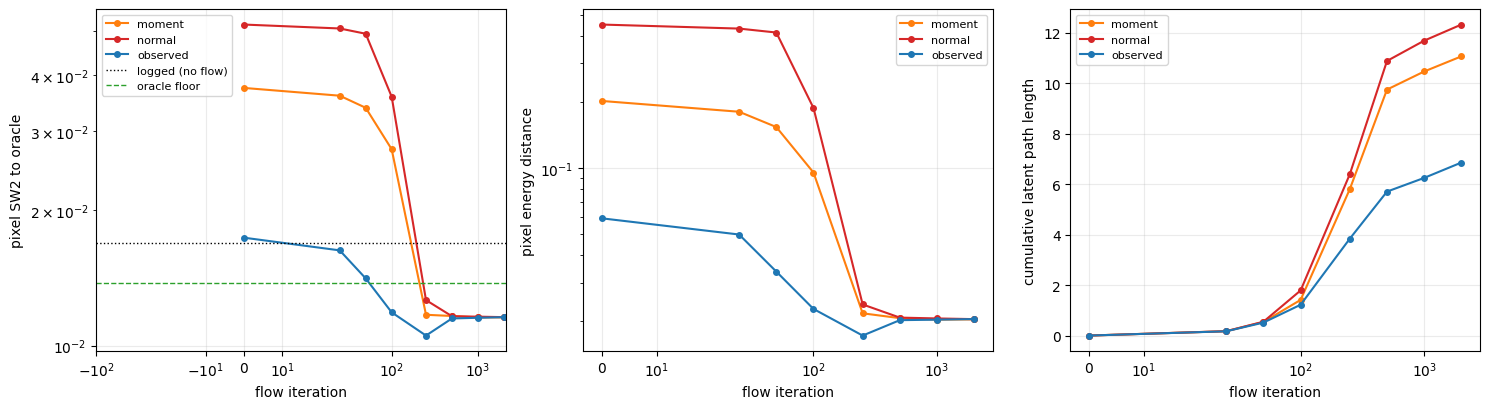

init,moment,normal,observed
iteration,,,
0,0.0374,0.0518,0.0174
25,0.0360,0.0508,0.0163
50,0.0338,0.0494,0.0141
100,0.0273,0.0358,0.0119
250,0.0117,0.0126,0.0105
500,0.0116,0.0116,0.0115
1000,0.0115,0.0116,0.0115
2000,0.0116,0.0116,0.0116


In [5]:
Y_target_dev = Y_target.to(device)
energy_kernel = RieszKernel()
flat = lambda x: x.reshape(len(x), -1).to(device)

records = []
for init, run in runs.items():
    order = sorted(run["snapshots"])
    path = 0.0
    previous = run["snapshots"][0]
    cumulative = {0: 0.0}
    for step in order[1:]:
        current = run["snapshots"][step]
        path += float((current - previous).norm(dim=1).mean())
        cumulative[step] = path
        previous = current
    for step in EVAL_AT:
        images = decode(run["snapshots"][step])
        records.append({
            "init": init, "iteration": step,
            "sw2": float(sliced_wasserstein(flat(images), flat(Y_target_dev), p=2, seed=0)),
            "energy": float(squared_mmd(energy_kernel, flat(images).double(),
                                        flat(Y_target_dev).double())),
            "transport": float((run["snapshots"][step] - run["start"]).norm(dim=1).mean()),
            "path": cumulative[step]})
import pandas as pd
curves = pd.DataFrame(records)

half = n_causal // 2
floor_sw2 = float(sliced_wasserstein(flat(Y_target_dev[:half]), flat(Y_target_dev[half:]),
                                     p=2, seed=0))
logged_sw2 = float(sliced_wasserstein(flat(data["Y_logged"][causal_idx]), flat(Y_target_dev),
                                      p=2, seed=0))
colours = {"observed": "tab:blue", "moment": "tab:orange", "normal": "tab:red"}
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
for init, group in curves.groupby("init"):
    for ax, column in zip(axes, ("sw2", "energy", "path")):
        ax.plot(group.iteration, group[column], marker="o", ms=4,
                color=colours[init], label=init)
axes[0].axhline(logged_sw2, ls=":", c="k", lw=1, label="logged (no flow)")
axes[0].axhline(floor_sw2, ls="--", c="tab:green", lw=1, label="oracle floor")
for ax, label in zip(axes, ("pixel SW2 to oracle", "pixel energy distance",
                            "cumulative latent path length")):
    ax.set_xlabel("flow iteration")
    ax.set_ylabel(label)
    ax.set_xscale("symlog", linthresh=25)
    ax.grid(alpha=0.25)
    ax.legend(fontsize=8)
axes[0].set_yscale("log")
axes[1].set_yscale("log")
fig.tight_layout()
plt.show()
curves.pivot(index="iteration", columns="init", values="sw2").round(4)

## 4. Content Preservation and the Per-Shape Position Law

Every decoded image is matched to its nearest sprite in the multi-factor bank, which
gives estimated shape / scale / orientation and a position at once, plus a
manifold-validity distance. The intervention leaves content untouched, so a sampler
that has learned it should reproduce the uniform factor marginals; and the position
shift is shape-dependent, so per-shape means test whether the *conditional* policy was
learned rather than only the pooled position law.

In [6]:
bank_flat = torch.as_tensor(
    bank.reshape(-1, 64 * 64), dtype=torch.float32, device=device)
n_shapes, n_scales, n_orientations = bank.shape[:3]
grid_index = np.indices((n_shapes, n_scales, n_orientations, 32, 32)).reshape(5, -1).T


def nearest_factors(images, chunk=4096, n_probe=500):
    "Nearest multi-factor bank sprite: returns factor codes, positions, distance."
    probe = images[:n_probe].to(device)
    best_distance = torch.full((len(probe),), float("inf"), device=device)
    best_index = torch.zeros(len(probe), dtype=torch.long, device=device)
    for start in range(0, len(bank_flat), chunk):
        block = bank_flat[start:start + chunk]
        distance = torch.cdist(probe, block)
        value, arg = distance.min(dim=1)
        improved = value < best_distance
        best_distance[improved] = value[improved]
        best_index[improved] = arg[improved] + start
    codes = grid_index[best_index.cpu().numpy()]
    return codes, best_distance.cpu().numpy()


rows = []
for label, images in ([("oracle", Y_target_dev)]
                      + [(f"{init} @{step}", decode(runs[init]["snapshots"][step]))
                         for init in runs for step in (0, 250, N_ITER)]):
    codes, distance = nearest_factors(images)
    shape_counts = np.bincount(codes[:, 0], minlength=n_shapes) / len(codes)
    rows.append({"sample": label,
                 "shape TV": float(np.abs(shape_counts - 1 / n_shapes).sum() / 2),
                 "scale TV": float(np.abs(np.bincount(codes[:, 1], minlength=n_scales)
                                          / len(codes) - 1 / n_scales).sum() / 2),
                 "orient TV": float(np.abs(np.bincount(codes[:, 2], minlength=n_orientations)
                                           / len(codes) - 1 / n_orientations).sum() / 2),
                 "off-manifold": float(np.median(distance)),
                 "posX": float(codes[:, 3].mean()), "posY": float(codes[:, 4].mean())})
content = pd.DataFrame(rows).set_index("sample").round(3)
content

,shape TV,scale TV,orient TV,off-manifold,posX,posY
sample,,,,,,
oracle,0.003,0.055,0.048,2.353,15.544,15.272
observed @0,0.007,0.051,0.040,3.094,15.618,15.182
observed @250,0.013,0.015,0.037,3.625,15.548,15.122
observed @2000,0.011,0.019,0.038,3.175,15.580,15.134
moment @0,0.265,0.253,0.052,6.025,15.478,14.708
moment @250,0.023,0.073,0.056,4.662,15.564,14.824
moment @2000,0.033,0.011,0.038,3.094,15.514,14.904
normal @0,0.283,0.399,0.037,6.438,15.286,15.334
normal @250,0.031,0.075,0.051,4.850,15.378,15.396


## 5. Decoded Particles Along the Flow

Rows are iterations; each block is one initialisation. This is where "passes through
invalid images" becomes visible even when a final latent metric looks acceptable.

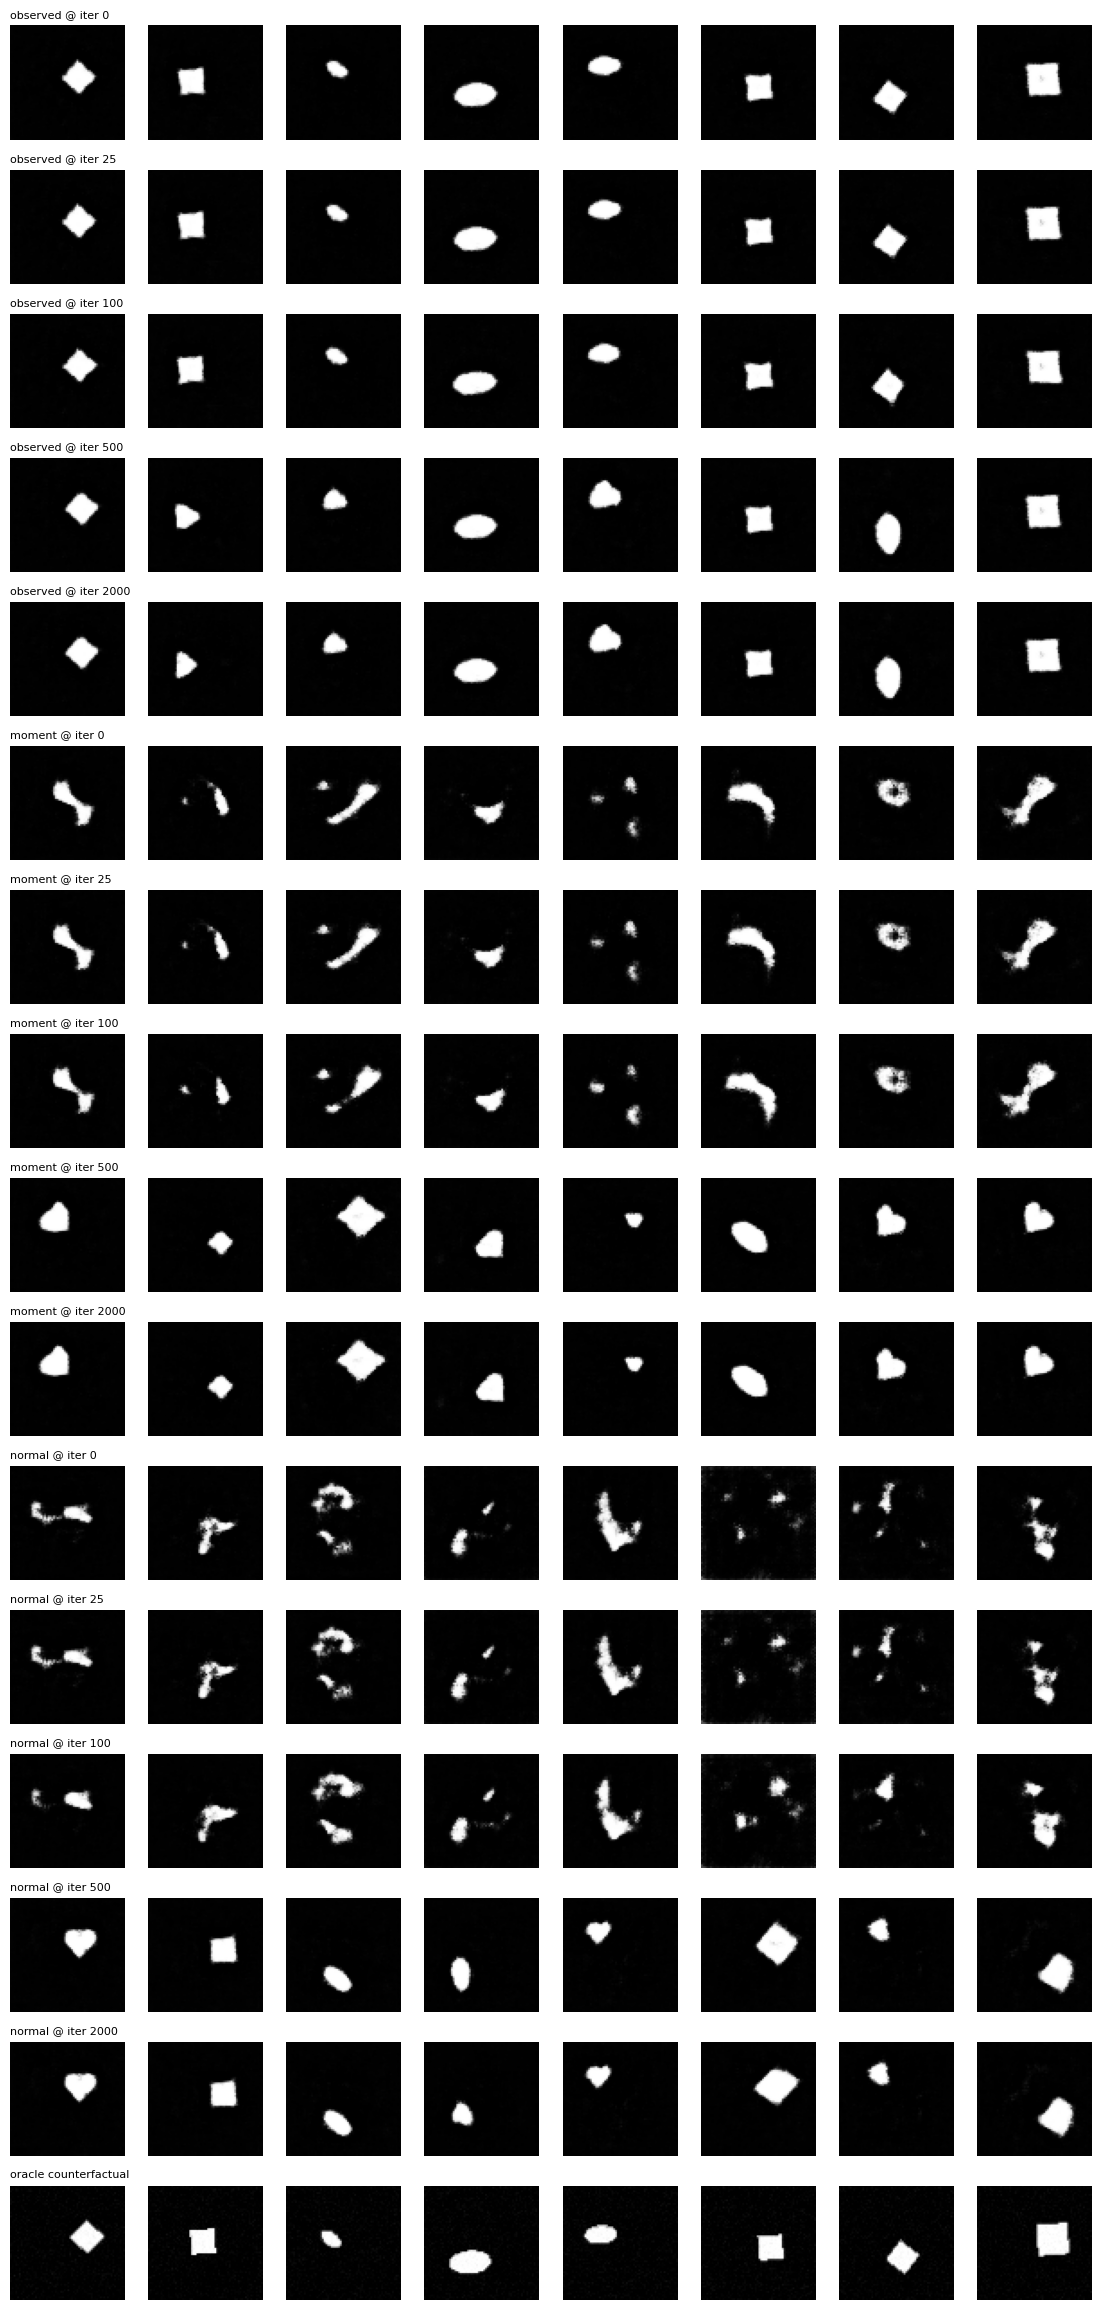

In [7]:
show_steps = [0, 25, 100, 500, N_ITER]
n_show = 8
fig, axes = plt.subplots(len(runs) * len(show_steps) + 1, n_show,
                         figsize=(1.4 * n_show, 1.45 * (len(runs) * len(show_steps) + 1)))
row = 0
for init in ("observed", "moment", "normal"):
    for step in show_steps:
        images = decode(runs[init]["snapshots"][step][:n_show]).reshape(-1, 64, 64).cpu()
        for j in range(n_show):
            axes[row, j].imshow(images[j], cmap="gray", vmin=0, vmax=1)
        axes[row, 0].set_title(f"{init} @ iter {step}", fontsize=8, loc="left")
        row += 1
oracle_images = Y_target[:n_show].reshape(-1, 64, 64)
for j in range(n_show):
    axes[row, j].imshow(oracle_images[j], cmap="gray", vmin=0, vmax=1)
axes[row, 0].set_title("oracle counterfactual", fontsize=8, loc="left")
for ax in axes.ravel():
    ax.axis("off")
fig.tight_layout()
plt.show()

## Findings

**Yes — on this design the observational initialisation helps, and the help is
entirely a budget effect.** Pixel SW2 to the oracle counterfactual images:

| iteration | observed | $N(\mu,\Sigma)$ | $N(0,I)$ |
|---|---|---|---|
| 0 | **0.0174** | 0.0374 | 0.0518 |
| 50 | **0.0141** | 0.0338 | 0.0494 |
| 100 | **0.0119** | 0.0273 | 0.0358 |
| 250 | 0.0105 | 0.0117 | 0.0126 |
| 500 | 0.0115 | 0.0116 | 0.0116 |
| 2000 | 0.0116 | 0.0116 | 0.0116 |

At a hundred iterations the observed start is $2.3$–$3.0\times$ closer than the
Gaussian starts; by five hundred the three are indistinguishable to four decimals.
The single-sprite design gave $0.0228/0.0229/0.0229$ — flat — so this design does
separate the conditions, but only while the budget binds. The asymptotic optimum is
unchanged, exactly as the design's Lipschitz argument allows: the logged law is
*close* to the target, not *equal* to it.

**Content preservation is the sharper separator, and it is what the single-sprite
design could not express.** Total-variation error of the recovered factor marginals
(nearest multi-factor bank sprite), and median distance to the nearest valid sprite:

| sample | shape TV | scale TV | off-manifold |
|---|---|---|---|
| oracle | 0.003 | 0.055 | 2.35 |
| observed @0 | **0.007** | **0.051** | **3.09** |
| $N(\mu,\Sigma)$ @0 | 0.265 | 0.253 | 6.03 |
| $N(0,I)$ @0 | 0.283 | 0.399 | 6.44 |
| observed @2000 | 0.011 | 0.019 | 3.18 |
| $N(0,I)$ @2000 | 0.021 | 0.021 | 3.13 |

The observational particles start with the correct shape and scale distributions and
on the sprite manifold; the Gaussian particles start with neither and spend the first
few hundred iterations acquiring them. By the end all three have learned the content —
the flow *can* generate it from scratch — which is why the final metrics agree.

**Transport confirms the mechanism**: final displacement $2.90$ from the observed
start against $5.78$ and $6.33$, and cumulative latent path length $6.9$ against
$11.1$ and $12.3$. The observational start reaches the same place along a path half as
long.

**Two honest limits on what this shows.**

1. *Attribution.* The earlier single-sprite ablation was measured only at
   convergence, so part of the contrast above comes from the iteration-resolved
   measurement rather than from the new design. Re-running the old design with
   snapshots would separate the two, and is cheap.
2. *The pooled position mean in Section 4 is uninformative by construction.* The
   three shape-dependent shifts nearly cancel when averaged ($v_0 + v_1 + v_2 = 0$),
   so posX/posY agree across conditions whatever the sampler does. The
   shape-conditional position law is the quantity that tests whether the
   *conditional* policy was learned, and it is not in this table yet.